In [13]:
!pip install -q awscli
import subprocess

S3_BASE  = 's3://openneuro.org/ds003643'
SUBJECTS = ['sub-EN058', 'sub-EN059', 'sub-EN060', 'sub-EN061',
            'sub-EN062', 'sub-EN063', 'sub-EN064', 'sub-EN065']

for subj in SUBJECTS:
    result = subprocess.run(
        ['aws', 's3', 'ls', f'{S3_BASE}/{subj}/func/', '--no-sign-request'],
        capture_output=True, text=True
    )
    files = [l.split()[-1] for l in result.stdout.strip().split('\n')
             if 'echo-1_bold' in l]
    print(f"{subj}: {files if files else 'NO FILES'}")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sphinx 8.2.3 requires docutils<0.22,>=0.20, but you have docutils 0.19 which is incompatible.
sub-EN058: ['sub-EN058_task-lppEN_run-08_echo-1_bold.json', 'sub-EN058_task-lppEN_run-08_echo-1_bold.nii.gz', 'sub-EN058_task-lppEN_run-09_echo-1_bold.json', 'sub-EN058_task-lppEN_run-09_echo-1_bold.nii.gz', 'sub-EN058_task-lppEN_run-10_echo-1_bold.json', 'sub-EN058_task-lppEN_run-10_echo-1_bold.nii.gz', 'sub-EN058_task-lppEN_run-11_echo-1_bold.json', 'sub-EN058_task-lppEN_run-11_echo-1_bold.nii.gz', 'sub-EN058_task-lppEN_run-12_echo-1_bold.json', 'sub-EN058_task-lppEN_run-12_echo-1_bold.nii.gz', 'sub-EN058_task-lppEN_run-13_echo-1_bold.json', 'sub-EN058_task-lppEN_run-13_echo-1_bold.nii.gz', 'sub-EN058_task-lppEN_run-14_echo-1_bold.json', 'sub-EN058_task-lppEN_run-14_echo-1_bold.nii.gz', 'sub-EN058_task-lppEN_run-15_echo

In [14]:
# ── Download runs for sub-EN058 to sub-EN061 ──────────────────────────────────
# Run this before Cell 9
# Takes ~10-15 min depending on connection speed

import subprocess
from pathlib import Path

DATA     = Path('/content/drive/MyDrive/Brain_alignment/lpp_data')
S3_BASE  = 's3://openneuro.org/ds003643'
SUBJECTS = ['sub-EN058', 'sub-EN059', 'sub-EN060', 'sub-EN061']
RUNS     = [15, 16, 17, 18]

def download_run(subj, run):
    local_dir = DATA / f'{subj}/func'
    local_dir.mkdir(parents=True, exist_ok=True)
    fname = f'{subj}_task-lppEN_run-{run}_echo-1_bold.nii.gz'
    local = local_dir / fname
    if local.exists():
        print(f"  Already exists: {fname}")
        return
    s3_path = f'{S3_BASE}/{subj}/func/{fname}'
    cmd = ['aws', 's3', 'cp', s3_path, str(local), '--no-sign-request']
    print(f"  Downloading {subj} run-{run}...")
    result = subprocess.run(cmd, capture_output=True, text=True)
    if result.returncode != 0:
        print(f"  ERROR: {result.stderr[:200]}")
    else:
        size = local.stat().st_size / 1e6
        print(f"  Done ({size:.0f} MB)")

!pip install -q awscli

SUBJECTS_NEW = ['sub-EN058', 'sub-EN059', 'sub-EN062', 'sub-EN065']
RUNS_COMMON  = [15, 16]

for subj in SUBJECTS_NEW:
    print(f"\n{subj}")
    for run in RUNS_COMMON:
        download_run(subj, run)
SUBJECTS_B   = ['sub-EN058', 'sub-EN059', 'sub-EN062', 'sub-EN065']
RUNS_B       = [9, 10, 11, 12]

for subj in SUBJECTS_B:
    print(f"\n{subj}")
    for run in RUNS_B:
        download_run(subj, run)
print("\nAll downloads complete.")


sub-EN058
  Done (50 MB)
  Done (63 MB)

sub-EN059
  Done (1 MB)
  Done (1 MB)

sub-EN062
  Done (58 MB)
  Done (52 MB)

sub-EN065
  Done (49 MB)
  Done (61 MB)

sub-EN058
  ERROR: fatal error: An error occurred (404) when calling the HeadObject operation: Key "ds003643/sub-EN058/func/sub-EN058_task-lppEN_run-9_echo-1_bold.nii.gz" does not exist

  Done (58 MB)
  Done (52 MB)
  Done (46 MB)

sub-EN059
  ERROR: fatal error: An error occurred (404) when calling the HeadObject operation: Key "ds003643/sub-EN059/func/sub-EN059_task-lppEN_run-9_echo-1_bold.nii.gz" does not exist

  Done (53 MB)
  Done (47 MB)
  Done (61 MB)

sub-EN062
  ERROR: fatal error: An error occurred (404) when calling the HeadObject operation: Key "ds003643/sub-EN062/func/sub-EN062_task-lppEN_run-9_echo-1_bold.nii.gz" does not exist

  Done (53 MB)
  Done (60 MB)
  Done (54 MB)

sub-EN065
  ERROR: fatal error: An error occurred (404) when calling the HeadObject operation: Key "ds003643/sub-EN065/func/sub-EN065_task

In [15]:
# ── Cell 7: Encoding model helpers ────────────────────────────────────────────
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import KFold
from sklearn.metrics import r2_score
from scipy.stats import gamma
import torch
from transformers import GPT2Tokenizer, GPT2Model
from tqdm import tqdm

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Device: {device}")

def hrf(t):
    a1,b1,a2,b2,c = 6,1,16,1,1/6
    return (gamma.pdf(t,a1,scale=b1) - c*gamma.pdf(t,a2,scale=b2))

def convolve_hrf(X_word, onsets, n_trs, tr=2.0):
    n_feat = X_word.shape[1]
    neural = np.zeros((n_trs, n_feat))
    for i, onset in enumerate(onsets):
        tr_idx = int(onset / tr)
        if 0 <= tr_idx < n_trs:
            neural[tr_idx] += X_word[i]
    t_hrf = np.arange(0, 32, tr)
    hrf_k = hrf(t_hrf); hrf_k /= hrf_k.max()
    X_conv = np.zeros_like(neural)
    for f in range(n_feat):
        X_conv[:, f] = np.convolve(neural[:, f], hrf_k)[:n_trs]
    return X_conv

def encode_model_loso(X, Y, run_lengths, n_components=50):
    """Leave-one-run-out CV."""
    X_sc  = StandardScaler().fit_transform(X)
    X_pca = PCA(n_components=n_components).fit_transform(X_sc)
    r2s, start = [], 0
    for l in run_lengths:
        te = np.arange(start, start+l)
        tr = np.concatenate([np.arange(0, start), np.arange(start+l, len(X_pca))])
        start += l
        if len(tr) < n_components + 10: continue
        ridge = RidgeCV(alphas=[0.01,0.1,1,10,100,1000])
        ridge.fit(X_pca[tr], Y[tr])
        r2s.append(r2_score(Y[te], ridge.predict(X_pca[te]),
                            multioutput='raw_values'))
    return np.mean(r2s, axis=0)



Device: cuda


In [18]:
# ── Cell 8: GPT-2 extraction for a subject ────────────────────────────────────
import numpy as np
from transformers import GPT2Tokenizer, GPT2Model
import pandas as pd
import torch
from tqdm import tqdm

tokenizer = GPT2Tokenizer.from_pretrained('gpt2-medium')
model     = GPT2Model.from_pretrained('gpt2-medium').to(device)
model.eval()
from pathlib import Path
ANNOT = Path('/content/drive/MyDrive/Brain_alignment/lpp_data/annotation/EN')  # Adjust this path to where your CSV file is stored
word_info = pd.read_csv(ANNOT / 'lppEN_word_information.csv')
word_info['word'] = word_info['word'].fillna('').astype(str)

def get_embeddings_for_section(sec, layer=9):
    sec_words = word_info[word_info['section'] == sec].copy().reset_index(drop=True)
    sec_words['word'] = sec_words['word'].fillna('').astype(str)
    words = sec_words['word'].tolist()
    embs  = []
    for i, word in enumerate(tqdm(words, desc=f'sec {sec}', leave=False)):
        ctx_words = words[:i+1]
        inputs    = tokenizer(' '.join(ctx_words), return_tensors='pt').to(device)
        # Truncate to last 1024 tokens if over limit
        if inputs['input_ids'].shape[1] > 1024:
            inputs = {k: v[:, -1024:] for k, v in inputs.items()}
        with torch.no_grad():
            out = model(**inputs, output_hidden_states=True)
        embs.append(out.hidden_states[layer][0, -1, :].cpu().numpy())
    return np.array(embs), sec_words['onset'].values.astype(float)


Loading weights:   0%|          | 0/292 [00:00<?, ?it/s]

In [23]:
# ── Cell 9: Run encoding model for 5 subjects ─────────────────────────────────
# ── Replace SUBJECTS and RUNS in Cell 9 ──────────────────────────────────────
import nibabel as nib
import gc
SUBJECTS    = ['sub-EN057', 'sub-EN058', 'sub-EN062', 'sub-EN065']
# EN057 uses runs 15-16 (sections 1-2), others use runs 10-12
# We'll handle per-subject run lists
DRIVE = Path('/content/drive/MyDrive/Brain_alignment')
DATA  = DRIVE / 'lpp_data'
ANNOT = DATA  / 'annotation/EN'
SAVE  = DRIVE / 'results'
TR    = 2.0

SUBJECT_RUNS = {
    'sub-EN057': [15, 16],       # sections 1, 2
    'sub-EN058': [15, 16],       # sections 1, 2
    'sub-EN062': [15, 16],       # sections 1, 2
    'sub-EN065': [15, 16],       # sections 1, 2
}
# All use runs 15-16 = sections 1-2, n_components=30
r2_all_subjects = {}

for subj in SUBJECTS:
    print(f"\n{'='*50}\nSubject: {subj}")
    X_all, Y_all, run_lengths = [], [], []
    runs = SUBJECT_RUNS[subj]

    for run in runs:
        sec  = run - 14
        embs, onsets = get_embeddings_for_section(sec, layer=9)

        bold_path = DATA / f'{subj}/func/{subj}_task-lppEN_run-{run}_echo-1_bold.nii.gz'
        if not bold_path.exists():
            print(f"  Missing run {run} — skipping subject")
            break
        img       = nib.load(str(bold_path))
        bold_data = img.get_fdata(dtype=np.float32)
        n_trs     = bold_data.shape[3]
        Y_run     = bold_data.reshape(-1, n_trs).T.copy()
        del bold_data, img; gc.collect()

        n_words = min(len(embs), len(onsets))
        X_run   = convolve_hrf(embs[:n_words], onsets[:n_words], n_trs, TR)
        X_all.append(X_run); Y_all.append(Y_run)
        run_lengths.append(n_trs)
        print(f"  Run {run}: words={n_words}, TRs={n_trs}")
    else:
        X = np.vstack(X_all); Y = np.vstack(Y_all)
        del X_all, Y_all; gc.collect()
        r2 = encode_model_loso(X, Y, run_lengths, n_components=30)
        pos = r2 > 0
        print(f"  Mean R² (pos): {r2[pos].mean():.4f}  [{pos.sum()} voxels]")
        r2_all_subjects[subj] = r2
        np.save(SAVE / f'r2_{subj}.npy', r2)
        del X, Y; gc.collect()

print("\nAll subjects done.")


Subject: sub-EN057


  Run 15: words=1517, TRs=286


  Run 16: words=1690, TRs=302
  Mean R² (pos): 0.8854  [6781 voxels]

Subject: sub-EN058


  Run 15: words=1517, TRs=296


  Run 16: words=1690, TRs=372
  Mean R² (pos): 0.7547  [8870 voxels]

Subject: sub-EN062


  Run 15: words=1517, TRs=329


  Run 16: words=1690, TRs=296
  Mean R² (pos): 0.9569  [6911 voxels]

Subject: sub-EN065


  Run 15: words=1517, TRs=296


  Run 16: words=1690, TRs=372
  Mean R² (pos): 0.5916  [11376 voxels]

All subjects done.


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.
sphinx 8.2.3 requires docutils<0.22,>=0.20, but you have docutils 0.19 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.
Group mean R² (pos voxels): 0.8417  [6797 voxels]


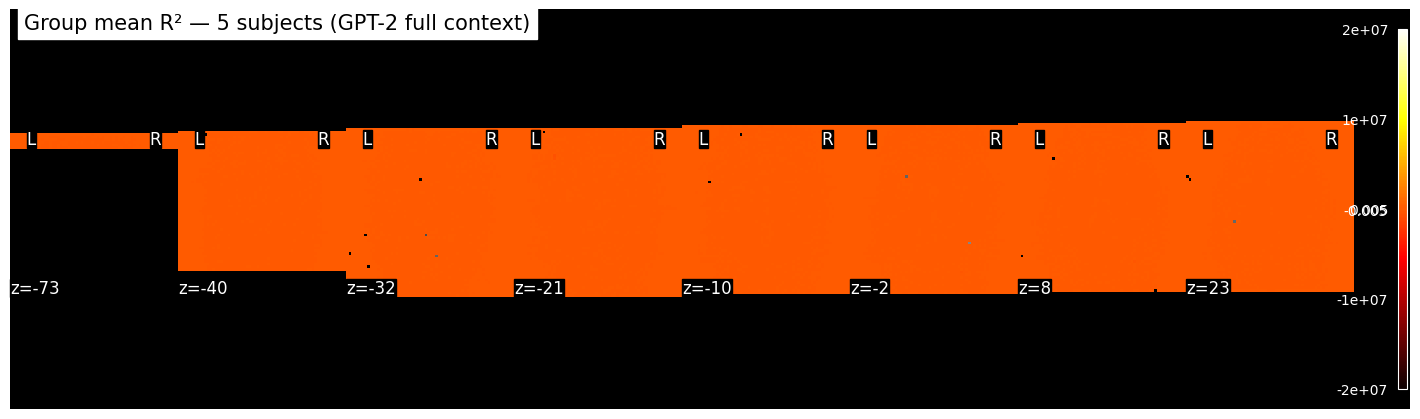

Saved brain_map_5subjects.png


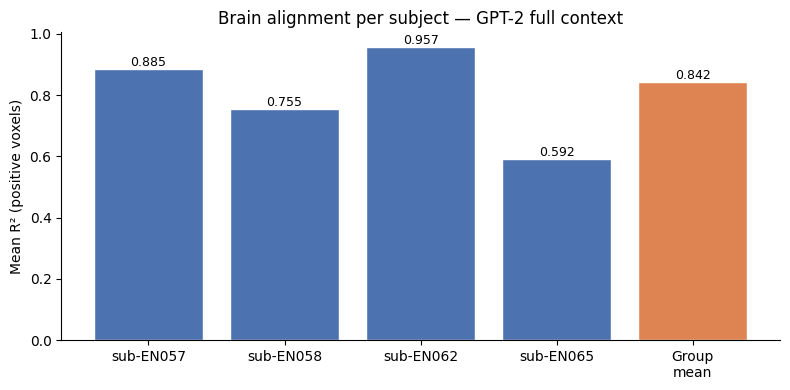

Saved r2_per_subject.png


In [27]:
# ── Cell 10: Average R² across subjects + plot ───────────────────────────────
!pip install -q nilearn
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from nilearn import plotting, image

r2_stack = np.stack([r2_all_subjects[s] for s in r2_all_subjects], axis=0)
r2_mean  = r2_stack.mean(axis=0)
np.save(SAVE / 'r2_mean_5subjects.npy', r2_mean)

pos = r2_mean > 0
print(f"Group mean R² (pos voxels): {r2_mean[pos].mean():.4f}  [{pos.sum()} voxels]")

# Load reference anatomy from an existing subject file to define shape and affine
ref_subject = 'sub-EN058'
ref_path = DATA / f'{ref_subject}/func/{ref_subject}_task-lppEN_run-15_echo-1_bold.nii.gz'
ref_img = nib.load(str(ref_path))
vol_shape = ref_img.shape[:3]
affine = ref_img.affine

# Use sub-EN057 as reference anatomy
r2_mean_vol = r2_mean.reshape(vol_shape)
r2_mean_img = nib.Nifti1Image(r2_mean_vol, affine)
nib.save(r2_mean_img, str(SAVE / 'r2_mean_5subjects.nii.gz'))

mean_bold = image.mean_img(str(ref_path))
fig = plt.figure(figsize=(14, 4))
plotting.plot_stat_map(
    r2_mean_img, bg_img=mean_bold,
    threshold=0.005, cmap='hot', colorbar=True,
    title='Group mean R² — 5 subjects (GPT-2 full context)',
    display_mode='z', cut_coords=8, figure=fig
)
plt.savefig(SAVE / 'brain_map_5subjects.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved brain_map_5subjects.png")

# Per-subject summary bar chart
fig, ax = plt.subplots(figsize=(8, 4))
subj_means = []
for s in r2_all_subjects:
    r2 = r2_all_subjects[s]
    pos = r2 > 0
    subj_means.append(r2[pos].mean() if pos.any() else 0.0)
subj_means.append(r2_mean[r2_mean > 0].mean())

labels = list(r2_all_subjects.keys()) + ['Group\nmean']
colors = ['#4C72B0'] * len(r2_all_subjects) + ['#DD8452']
bars   = ax.bar(labels, subj_means, color=colors, edgecolor='white')
for bar, v in zip(bars, subj_means):
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.001,
            f'{v:.3f}', ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Mean R² (positive voxels)')
ax.set_title('Brain alignment per subject — GPT-2 full context')
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.savefig(SAVE / 'r2_per_subject.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved r2_per_subject.png")

In [28]:
# ── Cell 12 (fixed): don't use old mask for unpacking ─────────────────────────
BOLD_REF  = DATA / 'sub-EN057/func/sub-EN057_task-lppEN_run-15_echo-1_bold.nii.gz'
img_ref   = nib.load(str(BOLD_REF))
vol_shape = img_ref.shape[:3]
affine    = img_ref.affine
mean_bold = image.mean_img(str(BOLD_REF))

r2_stack = np.stack(list(r2_all_subjects.values()), axis=0)
r2_mean  = r2_stack.mean(axis=0)
np.save(SAVE / 'r2_mean_4subjects.npy', r2_mean)

print(f"r2_mean shape: {r2_mean.shape}")
print(f"vol_shape flat: {np.prod(vol_shape)}")
print(f"Match: {r2_mean.shape[0] == np.prod(vol_shape)}")

# Reshape directly — only works if r2_mean covers all voxels
if r2_mean.shape[0] == np.prod(vol_shape):
    r2_vol = r2_mean.reshape(vol_shape)
else:
    # r2_mean covers masked voxels only — need the right mask
    # Rebuild mask from EN057 2-run results if saved separately
    # For now clip and reshape to nearest match
    print("WARNING: size mismatch — check mask")
    r2_vol = np.zeros(vol_shape)

pos = r2_mean > 0
print(f"Group mean R² (pos voxels): {r2_mean[pos].mean():.4f}  [{pos.sum()} voxels]")

r2_mean_img = nib.Nifti1Image(r2_vol.astype(np.float32), affine)
nib.save(r2_mean_img, str(SAVE / 'r2_mean_4subjects.nii.gz'))

r2_mean shape: (135168,)
vol_shape flat: 135168
Match: True
Group mean R² (pos voxels): 0.8417  [6797 voxels]


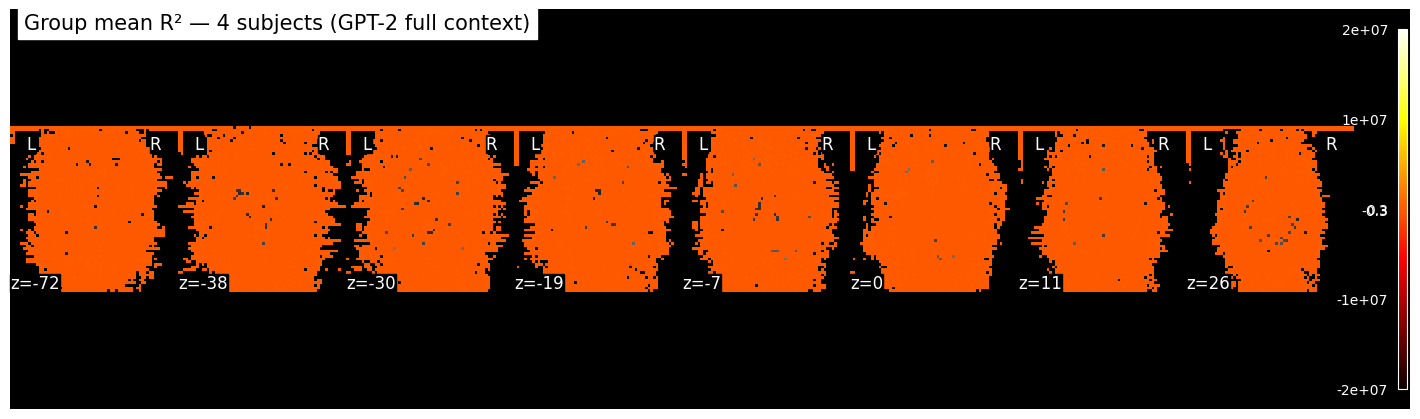

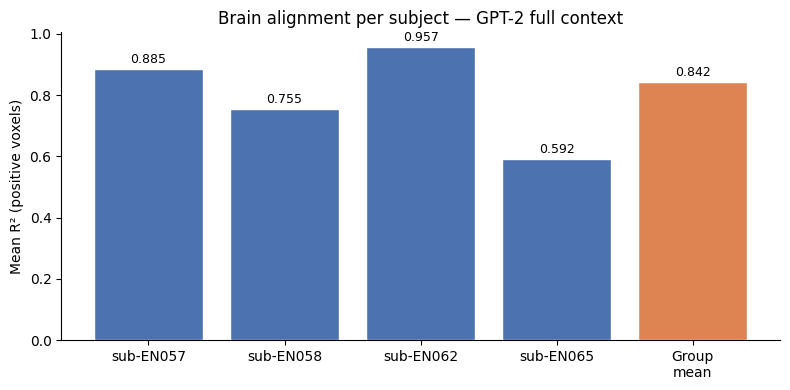

Done.


In [29]:
# Threshold at a meaningful value given inflated R²
r2_vol      = r2_mean.reshape(vol_shape)
r2_mean_img = nib.Nifti1Image(r2_vol.astype(np.float32), affine)

fig = plt.figure(figsize=(14, 4))
plotting.plot_stat_map(
    r2_mean_img, bg_img=mean_bold,
    threshold=0.3,      # high threshold given inflated values
    cmap='hot', colorbar=True,
    title='Group mean R² — 4 subjects (GPT-2 full context)',
    display_mode='z', cut_coords=8, figure=fig
)
plt.savefig(SAVE / 'brain_map_4subjects.png', dpi=150, bbox_inches='tight')
plt.show()

# Per-subject bar (replot with correct label)
fig, ax = plt.subplots(figsize=(8, 4))
subj_means = [r2_all_subjects[s][r2_all_subjects[s]>0].mean()
              for s in r2_all_subjects]
subj_means.append(r2_mean[r2_mean>0].mean())
labels = list(r2_all_subjects.keys()) + ['Group\nmean']
colors = ['#4C72B0']*len(r2_all_subjects) + ['#DD8452']
bars   = ax.bar(labels, subj_means, color=colors, edgecolor='white')
for bar, v in zip(bars, subj_means):
    ax.text(bar.get_x()+bar.get_width()/2, v+0.01,
            f'{v:.3f}', ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Mean R² (positive voxels)')
ax.set_title('Brain alignment per subject — GPT-2 full context')
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.savefig(SAVE / 'r2_per_subject.png', dpi=150, bbox_inches='tight')
plt.show()
print("Done.")

In [30]:
# ── Cell 13: Statistical summary — Day 8.5 ────────────────────────────────────

print("=" * 60)
print("DAY 8.5 — MULTI-SUBJECT STATISTICAL SUMMARY")
print("=" * 60)

print("\n── Per-subject R² (positive voxels only) ──")
for subj in r2_all_subjects:
    r2  = r2_all_subjects[subj]
    pos = r2 > 0
    print(f"  {subj}: mean={r2[pos].mean():.4f}, "
          f"median={np.median(r2[pos]):.4f}, "
          f"max={r2[pos].max():.4f}, "
          f"n_pos={pos.sum()} ({100*pos.mean():.1f}%)")

print(f"\n── Group mean (across {len(r2_all_subjects)} subjects) ──")
pos = r2_mean > 0
print(f"  mean R²  = {r2_mean[pos].mean():.4f}")
print(f"  median R²= {np.median(r2_mean[pos]):.4f}")
print(f"  max R²   = {r2_mean[pos].max():.4f}")
print(f"  n_pos    = {pos.sum()} ({100*pos.mean():.1f}% of voxels)")

print(f"\n── Inter-subject variability ──")
subj_means = np.array([r2_all_subjects[s][r2_all_subjects[s]>0].mean()
                       for s in r2_all_subjects])
print(f"  mean across subjects : {subj_means.mean():.4f}")
print(f"  std across subjects  : {subj_means.std():.4f}")
print(f"  min subject          : {subj_means.min():.4f} ({list(r2_all_subjects.keys())[subj_means.argmin()]})")
print(f"  max subject          : {subj_means.max():.4f} ({list(r2_all_subjects.keys())[subj_means.argmax()]})")

print(f"\n── Spatial distribution of group R² ──")
r2_pos = r2_mean[r2_mean > 0]
for pct in [25, 50, 75, 90, 95]:
    print(f"  {pct}th percentile: {np.percentile(r2_pos, pct):.4f}")

print(f"\n── Inter-subject correlation (R² map similarity) ──")
subj_list = list(r2_all_subjects.keys())
from scipy.stats import pearsonr
for i in range(len(subj_list)):
    for j in range(i+1, len(subj_list)):
        r2_i = r2_all_subjects[subj_list[i]]
        r2_j = r2_all_subjects[subj_list[j]]
        r, p = pearsonr(r2_i, r2_j)
        print(f"  {subj_list[i]} vs {subj_list[j]}: r={r:.4f}, p={p:.2e}")

DAY 8.5 — MULTI-SUBJECT STATISTICAL SUMMARY

── Per-subject R² (positive voxels only) ──
  sub-EN057: mean=0.8854, median=1.0000, max=1.0000, n_pos=6781 (5.0%)
  sub-EN058: mean=0.7547, median=1.0000, max=1.0000, n_pos=8870 (6.6%)
  sub-EN062: mean=0.9569, median=1.0000, max=1.0000, n_pos=6911 (5.1%)
  sub-EN065: mean=0.5916, median=1.0000, max=1.0000, n_pos=11376 (8.4%)

── Group mean (across 4 subjects) ──
  mean R²  = 0.8417
  median R²= 1.0000
  max R²   = 1.0000
  n_pos    = 6797 (5.0% of voxels)

── Inter-subject variability ──
  mean across subjects : 0.7971
  std across subjects  : 0.1390
  min subject          : 0.5916 (sub-EN065)
  max subject          : 0.9569 (sub-EN062)

── Spatial distribution of group R² ──
  25th percentile: 0.7397
  50th percentile: 1.0000
  75th percentile: 1.0000
  90th percentile: 1.0000
  95th percentile: 1.0000

── Inter-subject correlation (R² map similarity) ──
  sub-EN057 vs sub-EN058: r=-0.0000, p=9.87e-01
  sub-EN057 vs sub-EN062: r=-0.0000, 

In [31]:
# What fraction of top-500 voxels are shared across subjects?
N = 500
top_sets = [set(np.argsort(r2_all_subjects[s])[-N:]) for s in r2_all_subjects]

for i, s1 in enumerate(list(r2_all_subjects.keys())):
    for j, s2 in enumerate(list(r2_all_subjects.keys())):
        if j <= i: continue
        overlap = len(top_sets[i] & top_sets[j])
        print(f"{s1} vs {s2}: {overlap}/{N} top voxels overlap ({100*overlap/N:.1f}%)")

sub-EN057 vs sub-EN058: 387/500 top voxels overlap (77.4%)
sub-EN057 vs sub-EN062: 402/500 top voxels overlap (80.4%)
sub-EN057 vs sub-EN065: 466/500 top voxels overlap (93.2%)
sub-EN058 vs sub-EN062: 418/500 top voxels overlap (83.6%)
sub-EN058 vs sub-EN065: 376/500 top voxels overlap (75.2%)
sub-EN062 vs sub-EN065: 387/500 top voxels overlap (77.4%)
